In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
    ("tensorflow", "tensorflow==2.11.0",    "tensorflow==2.16.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


In [21]:
# ============================================================
# B6: Malware Detection using SimpleRNN (FIXED VERSION)
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout, Embedding, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
# -------------------- 1. LOAD DATA --------------------
df_raw = pd.read_csv(Path.cwd() / "Dataset" / "MalBehavD-V1-dataset.csv")

api_cols = [c for c in df_raw.columns if c != "labels"]

# -------------------- 2. BUILD VOCAB --------------------
all_apis = set()
for col in api_cols:
    all_apis.update(df_raw[col].dropna().astype(str).unique())

all_apis = sorted(list(all_apis))
api2idx = {api: i + 1 for i, api in enumerate(all_apis)}  # 0 = padding

print("Num APIs:", len(api2idx))

# -------------------- 3. SEQUENCE ENCODING --------------------
max_len = len(api_cols)

X = np.zeros((len(df_raw), max_len), dtype=np.int32)

for i, row in df_raw.iterrows():
    for j, col in enumerate(api_cols):
        api = row[col]
        if pd.notna(api):
            api = str(api)
            X[i, j] = api2idx.get(api, 0)

y = df_raw["labels"].values.astype(int)

# -------------------- 4. TRAIN / VAL / TEST SPLIT --------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)

# -------------------- 5. MODEL (SimpleRNN) --------------------
model = Sequential([
    Input(shape=(max_len,)),   # FIX UNBUILT ISSUE

    Embedding(
        input_dim=len(api2idx) + 1,
        output_dim=64,
        mask_zero=True
    ),

    SimpleRNN(64),   # 👈 SIMPLE RNN REPLACEMENT

    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# -------------------- 6. TRAINING --------------------
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# -------------------- 7. EVALUATION --------------------
y_prob = model.predict(X_test).flatten()
y_pred = (y_prob > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

Num APIs: 2834
Train: (1799, 176)
Val: (385, 176)
Test: (386, 176)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 176, 64)        │       181,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193,921 (757.50 KB)

 Trainable params: 193,921 (757.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 12s 219ms/step - accuracy: 0.7699 - loss: 0.5293 - val_accuracy: 0.8805 - val_loss: 0.3166
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 197ms/step - accuracy: 0.9150 - loss: 0.2395 - val_accuracy: 0.9221 - val_loss: 0.1992
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.9405 - loss: 0.1643 - val_accuracy: 0.9377 - val_loss: 0.1799
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 188ms/step - accuracy: 0.9450 - loss: 0.1614 - val_accuracy: 0.9351 - val_loss: 0.1698
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 175ms/step - accuracy: 0.9639 - loss: 0.1046 - val_accuracy: 0.9455 - val_loss: 0.1783
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 206ms/step - accuracy: 0.9711 - loss: 0.0856 - val_accuracy: 0.9532 - val_loss: 0.1745
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.9750 - loss: 0.0725 - val_accuracy: 0.9377 - val_loss: 0.2025
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step

Classification Report:
              precision    recall  f

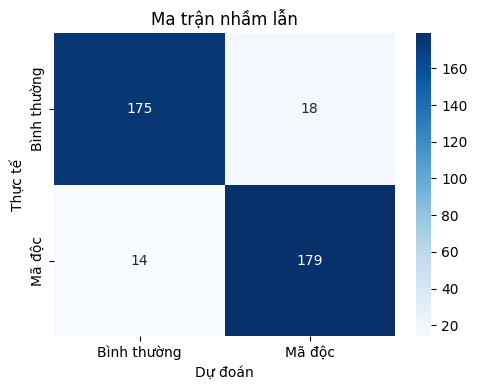

In [23]:
# -------------------- 8. CONFUSION MATRIX VISUALIZATION --------------------
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Tính lại nhãn dự đoán (nếu chưa lưu từ cell 7)
y_pred = (y_prob > 0.5).astype(int)

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)

# Vẽ heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Bình thường', 'Mã độc'],
    yticklabels=['Bình thường', 'Mã độc']
)

plt.title("Ma trận nhầm lẫn")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.tight_layout()
plt.show()